# Himalaya Domain

In [1]:
import sys
sys.path.insert(1, '/home/fainx/MyPythonLibrary/MAR-RECAP/libmar/')
import climbasis as climb
from climbasis import *
import domain as dom
import myplot
import numpy.ma as ma
from myplot import *
import obsinfo as obs
from obsinfo import *
from datetime import datetime
import mar
import cartopy.crs as ccrs
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point
import regionmask 
from scipy.stats import pearsonr, spearmanr
import cartopy.feature as cfeature
from sklearn.neighbors import BallTree

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.dates as mdates
import matplotlib.ticker as ticker
from matplotlib import colors
from matplotlib.lines import Line2D
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from matplotlib.colors import LogNorm

### Domain MAR

In [2]:
nx=ny=10

ds_nst=xr.open_dataset('/home/amoryc/NST.2000.01.01.00.GRq.nc')#['SH']#[nx:-nx,ny:-ny]
SH=ds_nst['SH'][nx:-nx,ny:-ny]
ICE=ds_nst['ICE'][nx:-nx,ny:-ny]
LONS,LATS = ds_nst.LON[nx:-nx,ny:-ny],ds_nst.LAT[nx:-nx,ny:-ny]

In [3]:
LONS = LONS.rename({"y": "Y", "x": "X"})
LATS = LATS.rename({"y": "Y", "x": "X"})
SH = SH.rename({"y": "Y", "x": "X"})
ICE = ICE.rename({"y": "Y", "x": "X"})

LONS = LONS.assign_coords(X=np.round(LONS.X.values))
LONS = LONS.assign_coords(Y=np.round(LONS.Y.values))

LATS = LATS.assign_coords(X=np.round(LATS.X.values))
LATS = LATS.assign_coords(Y=np.round(LATS.Y.values))

SH = SH.assign_coords(X=np.round(SH.X.values))
SH = SH.assign_coords(Y=np.round(SH.Y.values))

ICE = ICE.assign_coords(X=np.round(ICE.X.values))
ICE = ICE.assign_coords(Y=np.round(ICE.Y.values))

In [4]:
lat_min, lat_max = LATS.min().values, LATS.max().values
lon_min, lon_max = LONS.min().values, LONS.max().values

In [5]:
print('HIM MAR domain :')
print('LONS:', lon_min, lon_max )
print('LATS:', lat_min, lat_max)

HIM MAR domain :
LONS: 82.524 89.454056
LATS: 26.566393 30.46927


### Load RGI dataset
To extract glacier elevations

In [38]:
rgi_v6_ASE = gpd.read_file(
    "/bettik/PROJECTS/pr-regional-climate/fainx/HIM_SMB_OBS/RGI/v6/15_rgi60_SouthAsiaEast.shp"
)
rgi_v6_ASE.columns

Index(['RGIId', 'GLIMSId', 'BgnDate', 'EndDate', 'CenLon', 'CenLat',
       'O1Region', 'O2Region', 'Area', 'Zmin', 'Zmax', 'Zmed', 'Slope',
       'Aspect', 'Lmax', 'Status', 'Connect', 'Form', 'TermType', 'Surging',
       'Linkages', 'Name', 'geometry'],
      dtype='object')

In [7]:
mera_info = rgi_v6_ASE[rgi_v6_ASE["RGIId"] == 'RGI60-15.03586']
mera_info

,RGIId,GLIMSId,BgnDate,EndDate,CenLon,CenLat,O1Region,O2Region,Area,Zmin,...,Aspect,Lmax,Status,Connect,Form,TermType,Surging,Linkages,Name,geometry
3585,RGI60-15.03586,G086889E27729N,20001030,-9999999,86.889147,27.728914,15,2,1.436,4955,...,360,2789,0,0,1,0,9,9,None,"POLYGON ((86.89027 27.73842, 86.89071 27.73846..."


### Load WGMS dataset

In [68]:
wgms_folder ='/bettik/PROJECTS/pr-regional-climate/fainx/PAMIR_SMB_OBS/WGMS-FoG-2026-02-10/'
wgms_file_glacier = 'glacier.csv'
wgms_file_smb = 'mass_balance.csv'

In [69]:
wgms_glacier_all_df = pd.read_csv(wgms_folder+wgms_file_glacier , sep=",")
wgms_smb_all_df = pd.read_csv(wgms_folder+wgms_file_smb , sep=",")

#### For some reason, RGI 6.0 ref of MERA and TRAMBAU are not included in WGMS data files.
#### Add them manually // to be checked with Fanny

In [70]:
# Remplacer 'MERA' par 'RGI60-15.03586' dans la colonne 'short_name'
wgms_glacier_all_df.loc[wgms_glacier_all_df['short_name'] == 'MERA', 'short_name'] = 'RGI60-15.03586'
wgms_glacier_all_df.loc[wgms_glacier_all_df['short_name'] == 'TRAMBAU', 'short_name'] = 'RGI60-15.02662'

In [71]:
# Merge avec toutes les colonnes de wgms_glacier_df_sel
wgms_all_df = wgms_smb_all_df.merge(
    wgms_glacier_all_df,  # On inclut TOUTES les colonnes de wgms_glacier_df_sel
    left_on="glacier_id",
    right_on="id",
    how="inner"  # Garde uniquement les lignes avec une correspondance
)

# Supprimer la colonne "id" dupliquée (car elle vient de wgms_glacier_df_sel)
wgms_all_df = wgms_all_df.drop(columns=["id"])

# Renommer la colonne "longitude" en "lon"
wgms_all_df = wgms_all_df.rename(columns={"longitude": "lon"})
# Renommer la colonne "longitude" en "lon"
wgms_all_df = wgms_all_df.rename(columns={"latitude": "lat"})
#wgms_all_df.columns

In [72]:
# Selectionner les glacier WGMS incluent dans le domaine MAR HIM
wgms_df = wgms_all_df[
    (wgms_all_df['lat'].between(lat_min, lat_max)) &
    (wgms_all_df['lon'].between(lon_min, lon_max))
]

In [73]:
# Get glacier altitudes from RGI and include them to WGMS Dussaillant dataset
rgi_v6_ASE["key"] = rgi_v6_ASE["RGIId"]#.str[-5:]

wgms_df["rgi60_ids"] = wgms_df["rgi60_ids"].astype(str)
wgms_df["key"] = wgms_df["rgi60_ids"]# .str[-5:]

wgms_df = wgms_df.merge(
    rgi_v6_ASE[["key", 'Zmin', 'Zmax', 'Zmed']], # checked that area, lon, and lat reported by Dussaillant are identical to RGI v6 database => OK
    on="key",
    how="left"
)

#wgms_df = wgms_df.drop(columns=["key"])
wgms_df.columns

/tmp/ipykernel_1884652/2848403550.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  wgms_df["rgi60_ids"] = wgms_df["rgi60_ids"].astype(str)
/tmp/ipykernel_1884652/2848403550.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  wgms_df["key"] = wgms_df["rgi60_ids"]# .str[-5:]


Index(['country_x', 'glacier_name', 'glacier_id', 'outline_id', 'year',
       'time_system', 'begin_date', 'begin_date_unc', 'midseason_date',
       'midseason_date_unc', 'end_date', 'end_date_unc', 'winter_balance',
       'winter_balance_unc', 'summer_balance', 'summer_balance_unc',
       'annual_balance', 'annual_balance_unc', 'ela_position', 'ela',
       'ela_unc', 'aar', 'area', 'investigators', 'agencies', 'references_x',
       'remarks_x', 'country_y', 'short_name', 'names', 'lat', 'lon',
       'gtng_region', 'glims_id', 'rgi50_ids', 'rgi60_ids', 'rgi70_ids',
       'wgi_id', 'parent_glacier_id', 'references_y', 'remarks_y', 'key',
       'Zmin', 'Zmax', 'Zmed'],
      dtype='object')

In [74]:
# Grouper par 'glacier_name' et garder la première ligne pour chaque glacier
ds_first_per_glacier = wgms_df.groupby('glacier_name').first().reset_index()

# Afficher le résultat
#print(ds_first_per_glacier)

In [75]:
noms_uniques = wgms_df["glacier_name"].unique()
nombre_de_glaciers = len(noms_uniques)

print(f"Noms uniques : {noms_uniques}")
print(f"Nombre de glaciers uniques : {nombre_de_glaciers}")

Noms uniques : ['KANGWURE' 'CHANGMEKHANGPU' 'AX010' 'MERA' 'POKALDE' 'RIKHA SAMBA'
 'TRAMBAU' 'WEST CHANGRI NUP' 'YALA']
Nombre de glaciers uniques : 9


In [76]:
# Grouper par 'glacier_name' et stocker chaque groupe dans un dictionnaire
glaciers_dict = {name: group for name, group in wgms_df.groupby("glacier_name")}

for glacier_name, glacier_data in glaciers_dict.items():
    print(f"Glacier: {glacier_name} | Nombre de lignes: {len(glacier_data)}")

Glacier: AX010 | Nombre de lignes: 5
Glacier: CHANGMEKHANGPU | Nombre de lignes: 7
Glacier: KANGWURE | Nombre de lignes: 4
Glacier: MERA | Nombre de lignes: 17
Glacier: POKALDE | Nombre de lignes: 15
Glacier: RIKHA SAMBA | Nombre de lignes: 15
Glacier: TRAMBAU | Nombre de lignes: 8
Glacier: WEST CHANGRI NUP | Nombre de lignes: 14
Glacier: YALA | Nombre de lignes: 14


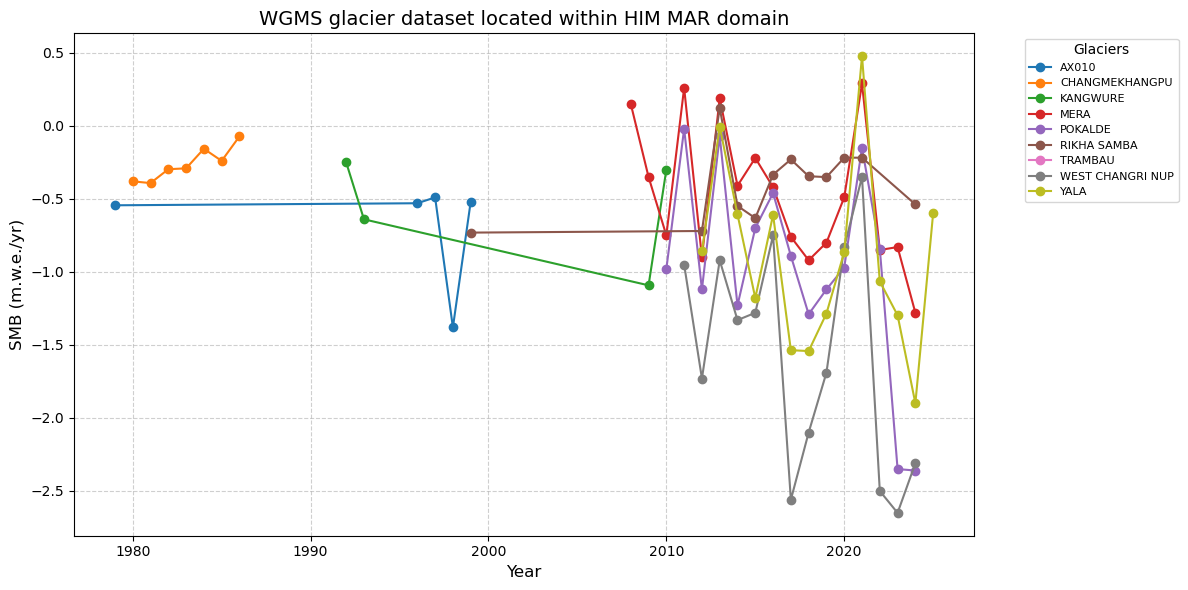

In [77]:
plt.figure(figsize=(12, 6))  
 
for glacier_name, glacier_data in wgms_df.groupby("glacier_name"):
    glacier_data = glacier_data.dropna(subset=["annual_balance"])

    plt.plot(
        glacier_data["year"],
        glacier_data["annual_balance"],
        marker="o",  # Ajoute des marqueurs pour chaque point
        linestyle="-",  # Ligne pleine
        label=glacier_name,
        linewidth=1.5,
    )

plt.xlabel("Year", fontsize=12)
plt.ylabel("SMB (m.w.e./yr)", fontsize=12)
plt.title("WGMS glacier dataset located within HIM MAR domain", fontsize=14)
plt.grid(True, linestyle="--", alpha=0.6) 
plt.legend(
    title="Glaciers",
    bbox_to_anchor=(1.05, 1),  # Place la légende à l'extérieur du graphique
    loc="upper left",
    fontsize=8,
)

plt.tight_layout()
plt.show()

In [78]:
# Liste des glaciers à exclure
glaciers_to_exclude = ["AX010", "CHANGMEKHANGPU", "KANGWURE"]

wgms_df_sel = wgms_df[
    ~wgms_df["glacier_name"].isin(glaciers_to_exclude)
]

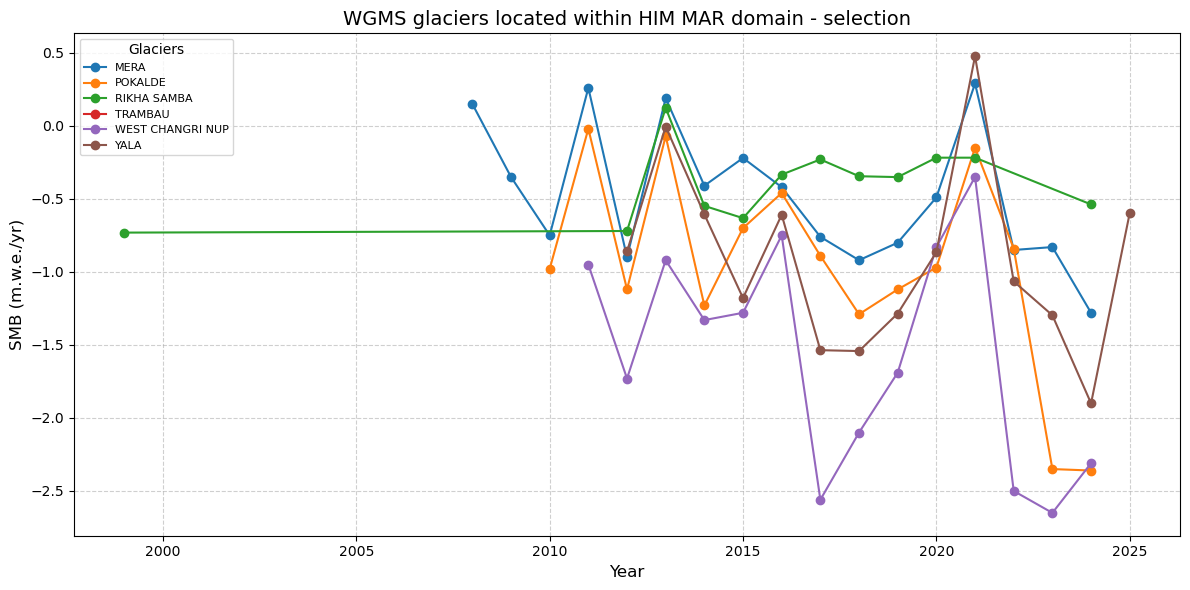

In [79]:
plt.figure(figsize=(12, 6))  
 
for glacier_name, glacier_data in wgms_df_sel.groupby("glacier_name"):
    glacier_data = glacier_data.dropna(subset=["annual_balance"])
    plt.plot(
        glacier_data["year"],
        glacier_data["annual_balance"],
        marker="o",  # Ajoute des marqueurs pour chaque point
        linestyle="-",  # Ligne pleine
        label=glacier_name,
        linewidth=1.5,
    )

plt.xlabel("Year", fontsize=12)
plt.ylabel("SMB (m.w.e./yr)", fontsize=12)
plt.title("WGMS glaciers located within HIM MAR domain - selection", fontsize=14)
plt.grid(True, linestyle="--", alpha=0.6)   
plt.legend(
    title="Glaciers",
#    bbox_to_anchor=(1.05, 1),  # Place la légende à l'extérieur du graphique
    loc="upper left",
    fontsize=8,
)

plt.tight_layout()
plt.show()

/tmp/ipykernel_1884652/783923998.py:71: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


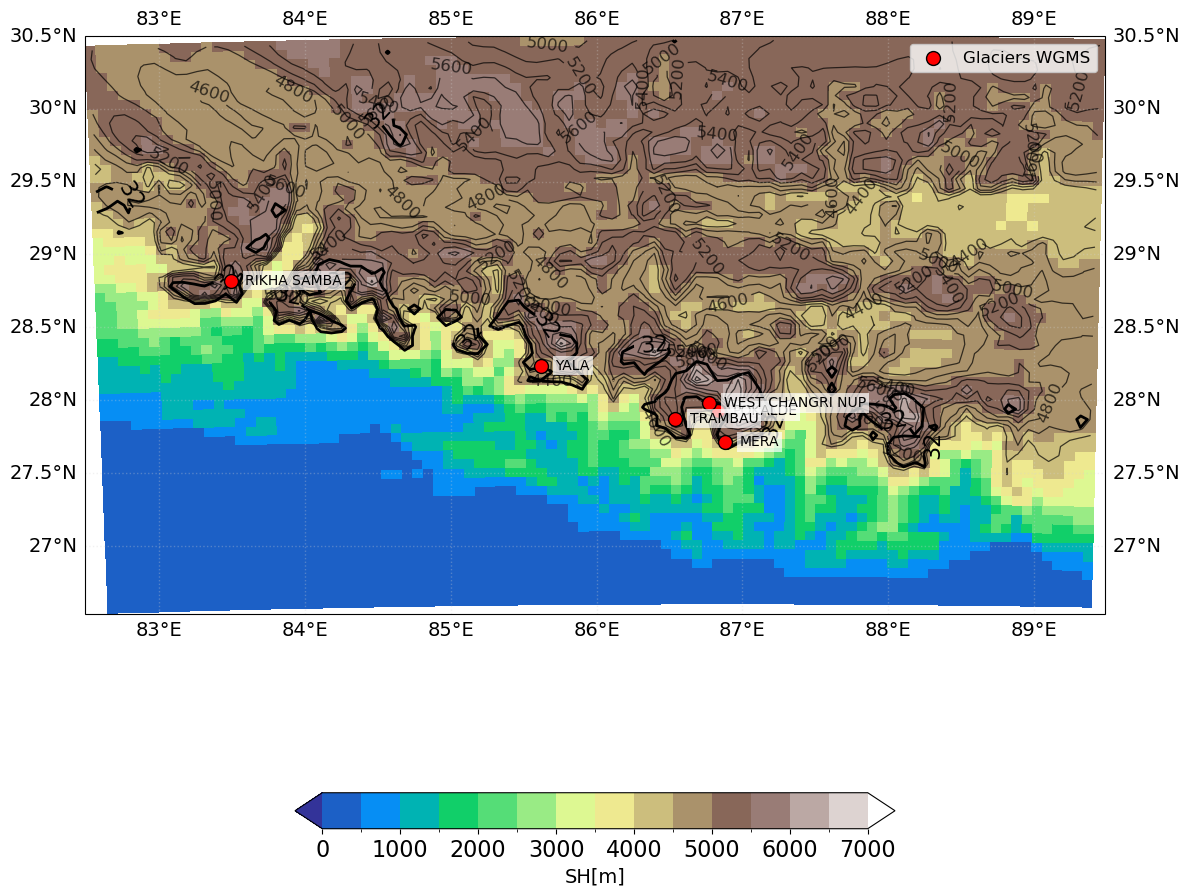

In [80]:
# --- Configuration de la carte ---
ice_level = 32  # % of ice on grid cell
clevs = np.arange(0, 7500, 500)
cmap_mod = plt.get_cmap('terrain')
norm = mcolors.BoundaryNorm(boundaries=clevs, ncolors=cmap_mod.N, extend="both")

fig, ax = plt.subplots(figsize=(12, 12), subplot_kw={'projection': ccrs.PlateCarree()})

# --- Ajout des données SH et ICE ---
im = ax.pcolormesh(LONS, LATS, SH, transform=ccrs.PlateCarree(), cmap=cmap_mod, norm=norm, shading='auto')
ax.set_aspect(1.0)

SH1 = ax.contour(LONS, LATS, SH,
                 levels=[4400, 4600, 4800, 5000, 5200, 5400, 5600, 5800, 6000, 6200, 6400, 6600, 6800, 7000],
                 colors="k", linewidths=0.9, alpha=0.7, transform=ccrs.PlateCarree())
ax.clabel(SH1, inline=True, fontsize=12, fmt="%d")

ICE2 = ax.contour(LONS, LATS, ICE, levels=[ice_level], colors="black", linewidths=2.0, alpha=1.0, transform=ccrs.PlateCarree())
ax.clabel(ICE2, inline=True, fontsize=16, fmt="%d")

# --- Ajout des glaciers depuis wgms_smb_filtered_sel ---
# Extraire les coordonnées et noms uniques des glaciers
glaciers = wgms_df_sel[["glacier_name", "lat", "lon"]].drop_duplicates()
glaciers = glaciers.dropna(subset=["lat", "lon"])  # Supprimer les lignes sans coordonnées

# Tracer un point pour chaque glacier
ax.scatter(
    glaciers["lon"],  # Longitude en X
    glaciers["lat"],   # Latitude en Y
    color="red",            # Couleur des points
    s=100,                  # Taille des points
    marker="o",            # Forme des points (cercle)
    edgecolor="black",     # Bordure noire
    linewidth=1,           # Épaisseur de la bordure
    transform=ccrs.PlateCarree(),
    label="Glaciers WGMS",  # Légende
    zorder=10,             # Ordre d'affichage (au-dessus des contours)
)

# Ajouter les noms des glaciers à côté des points
for i, row in glaciers.iterrows():
    ax.text(
        row["lon"] + 0.1,  # Décalage en longitude pour éviter le chevauchement
        row["lat"],         # Latitude
        row["glacier_name"],     # Texte (nom du glacier)
        fontsize=10,
        color="black",
        transform=ccrs.PlateCarree(),
        ha="left",               # Alignement horizontal
        va="center",             # Alignement vertical
        zorder=10,
        bbox=dict(facecolor="white", alpha=0.7, edgecolor="none", pad=2),  # Fond blanc pour meilleure lisibilité
    )

# --- Personnalisation de la carte ---
gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True, linewidth=1, color="lightgray", alpha=0.3, linestyle=":")
gl.xlabel_style = {"size": 14}
gl.ylabel_style = {"size": 14}

# Barre de couleur
cbar_ax = fig.add_axes([0.25, 0.08, 0.5, 0.03])  # [left, bottom, width, height]
cbar = fig.colorbar(im, cax=cbar_ax, orientation="horizontal")
cbar.set_label(f"{'SH'}[{'m'}]", fontsize=14)
cbar.ax.tick_params(labelsize=16)

# Ajouter une légende pour les points
ax.legend(loc="upper right", fontsize=12)

# Ajustement des marges
fig.subplots_adjust(left=0.2, right=0.8, top=0.95, bottom=0.1, wspace=0.05, hspace=0.2)
plt.tight_layout()
plt.show()

In [81]:
# Extraire Lat et lon des glaciers WGMS du domain HIM de MAR 
glaciers_coords = wgms_df_sel[["glacier_name","glacier_id","lat", "lon","Zmed","Zmin","Zmax"]].drop_duplicates()
print(glaciers_coords)

        glacier_name  glacier_id        lat        lon    Zmed    Zmin    Zmax
16              MERA        3996  27.713005  86.880918  5470.0  4955.0  6009.0
33           POKALDE        3997  27.926560  86.831370  5536.0  5380.0  5637.0
48       RIKHA SAMBA        1516  28.820000  83.490000  5809.0  5380.0  6513.0
63           TRAMBAU      216959  27.873000  86.538000     NaN     NaN     NaN
71  WEST CHANGRI NUP       10401  27.981080  86.770730  5402.0  5137.0  6335.0
85              YALA         912  28.236500  85.617900  5352.0  5093.0  5671.0


### Load MAR data

In [61]:
domain = 'GRq'

In [62]:
sourceData_1='/bettik/PROJECTS/pr-regional-climate/santolam/MARout_post/' + domain +'/spin2/work/monthly/'
sourceData_2='/bettik/PROJECTS/pr-regional-climate/fainx/'
sourceData_3='/bettik/PROJECTS/pr-regional-climate/santolam/HARv2/'
folder_figure = '/bettik/PROJECTS/pr-regional-climate/fainx/figures/' + domain +'/'

In [45]:
variable='SMB' 
#"Surface Mass Balance (SMB~SF+RF-RU-SU-SW)" 

ds_SMB = xr.open_mfdataset(sourceData_1 + "SMB_monsum_MARv3.14_ER5_spin2_GRq_*.nc").SMB.sel(SECTOR=1).load()

ds_SMB = ds_SMB.assign_coords(X=np.round(ds_SMB.X.values))
ds_SMB = ds_SMB.assign_coords(Y=np.round(ds_SMB.Y.values))
ds_SMB = ds_SMB.rename({'TIME': 'time'})

# Enlever k pixels sur les contours
ds_SMB = ds_SMB[:,nx:-nx,nx:-nx]

# Passer en m WE/yr
ds_SMB = ds_SMB/1000

ds_SMB = ds_SMB.chunk({"time": 50, "Y": 62, "X": 96})

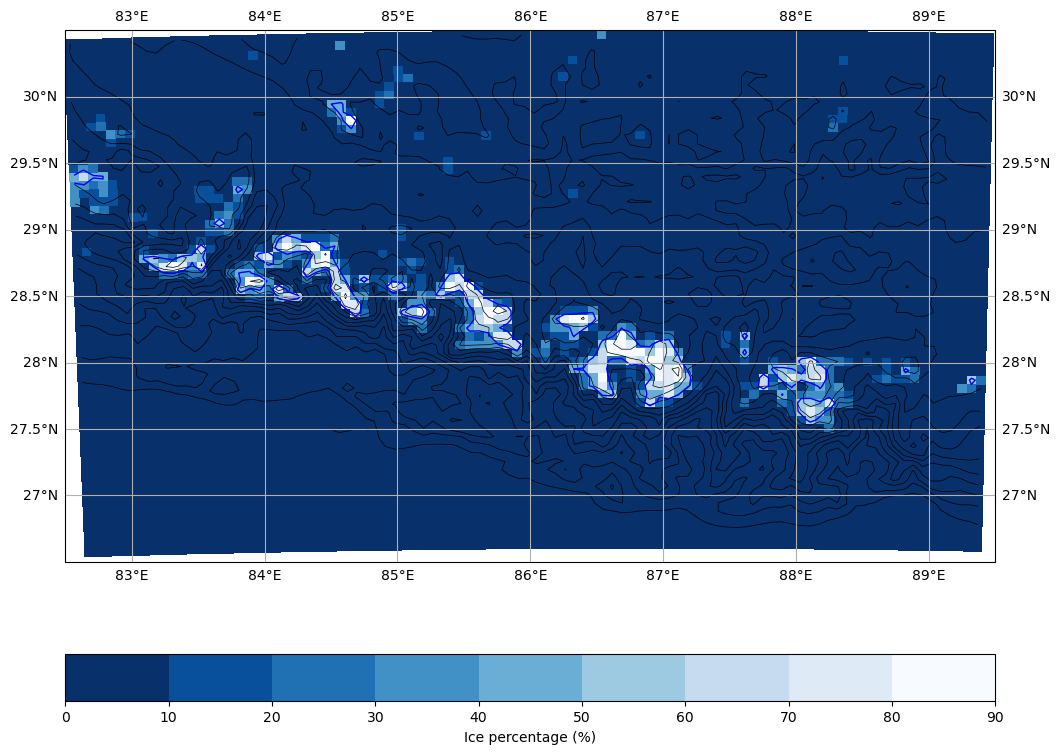

In [46]:
ice_level = 40 # Seuil à partir duquel on considère qu'on observe de la glace

clevs = np.arange(0, 100, 10) # Echelle de couleur de 0 à 100% tous les 10%
cmap = plt.get_cmap("Blues_r") # Palette de couleur bleu (reverse) pour voir le % de glace par grille
norm = mcolors.BoundaryNorm(boundaries=clevs, ncolors=cmap.N) 


fig, ax = plt.subplots(figsize=(12,12),subplot_kw={'projection': ccrs.PlateCarree()}) # Utilisation de la projection plate carré

#### Courbes de niveau (tous les 500m) ####
SH_plot = ax.contour(LONS, LATS, SH, 
           levels=[500,1000,1500,2000,2500,3000,3500,4000,4500,5000,5500,6000,6500,7000], # Affichage des lignes de topographie
           colors="k", linewidths=0.5,
           transform=ccrs.PlateCarree())
#ax.clabel(SH, SH.levels, inline=True, fontsize=6, fmt="%d", inline_spacing=1) # Affiche valeur sur les courbes

#### Countour glaciers ####
ax.contour(LONS, LATS, ICE, 
           levels=[ice_level], # Défini les lignes de contour des glaciers (bleu) où la grille dépasse la valeur de ice_level 
           colors="b", linewidths=1,
           transform=ccrs.PlateCarree())

# #### Mera Peak coord ####
# ax.plot(merap_lon, merap_lat,  # Coord exact du Mera Peak
#         marker='o', markersize=10,
#         markeredgecolor='black', markerfacecolor='red',
#         transform=ccrs.PlateCarree())

#### Percentage of ice ####
im = ax.pcolormesh(LONS, LATS, ICE, 
                   cmap=cmap, norm=norm, # Affiche la couleur du % de glace
                   transform=ccrs.PlateCarree(),
                   shading="auto")
ax.set_extent([82.5, 89.5, 26.5, 30.5], crs=ccrs.PlateCarree()) # Défini les limites (lon, lat) du domaine observable 
#ax.set_extent([86.7, 87.1, 27.6, 27.9], crs=ccrs.PlateCarree()) # Défini les limites (lon, lat) du domaine observable zoom

ax.gridlines(draw_labels=True) # Grille de lattitude et longitude
plt.colorbar(im, orientation="horizontal", pad=0.1, label="Ice percentage (%)") # Paramètres de la barre d'altitude (disposition horizontale / taille / légende)
plt.show()

In [47]:
# Dans cette analyse je travaille uniquement sur les données SMB des surfaces englaçées
# Ca plot différement sur la carte ci dessous - revoir le sens de SECTOR = 0
ds_SMB_ice = ds_SMB.where(ICE > 0)

In [ ]:
glacier_lats

In [63]:
# 2. Initialiser les colonnes pour les indices X et Y
glaciers_coords["iX"] = np.nan
glaciers_coords["iY"] = np.nan

# 3. Pour chaque glacier, trouver le point de grille le plus proche
for idx, row in glaciers_coords.iterrows():
    # Coordonnées du glacier
    glacier_lat = row["lat"]
    glacier_lon = row["lon"]

    # Calculer la distance entre le glacier et tous les points de grille
    dist = np.sqrt((LATS - glacier_lat)**2 + (LONS - glacier_lon)**2)

    # Trouver l'index 1D du point le plus proche
    idx_1d = dist.argmin().item()

    # Convertir en indices 2D (Y, X)
    iY, iX = np.unravel_index(idx_1d, dist.shape)

    # Stocker les indices dans le DataFrame
    glaciers_coords.at[idx, "iY"] = iY
    glaciers_coords.at[idx, "iX"] = iX

# 4. (Optionnel) Ajouter les caractéristiques de la maille (altitude, %ICE, etc.)
glaciers_coords["SH"] = np.nan
glaciers_coords["ICE"] = np.nan

for idx, row in glaciers_coords.iterrows():
    iY, iX = int(row["iY"]), int(row["iX"])
    glaciers_coords.at[idx, "SH"] = SH[iY, iX].item()
    glaciers_coords.at[idx, "ICE"] = ICE[iY, iX].item()

# 5. Afficher le résultat
print(glaciers_coords)

        glacier_name  glacier_id        lat        lon    Zmed    Zmin  \
16              MERA        3996  27.713005  86.880918  5470.0  4955.0   
33           POKALDE        3997  27.926560  86.831370  5536.0  5380.0   
48       RIKHA SAMBA        1516  28.820000  83.490000  5809.0  5380.0   
63           TRAMBAU      216959  27.873000  86.538000     NaN     NaN   
71  WEST CHANGRI NUP       10401  27.981080  86.770730  5402.0  5137.0   
85              YALA         912  28.236500  85.617900  5352.0  5093.0   

      Zmax    iX    iY           SH        ICE  
16  6009.0  60.0  17.0  4831.354492  67.500000  
33  5637.0  59.0  21.0  5070.167969   0.000000  
48  6513.0  13.0  35.0  5399.826660  46.913578  
63     NaN  55.0  20.0  5477.827148  90.123459  
71  6335.0  58.0  21.0  4996.849609  13.580246  
85  5671.0  42.0  26.0  4874.110352  53.086418  
